# Домашнее задание: продуктовые метрики

**Данные:** `metrics_users.csv`, `metrics_events.csv` (синтетические). **Формат сдачи:** заполненный notebook с выводами и работающим кодом. **Оценивание:** 100 баллов.


In [ ]:
import pandas as pd
users = pd.read_csv('/content/metrics_users.csv', parse_dates=['signup_date'])
events = pd.read_csv('/content/metrics_events.csv', parse_dates=['event_date'])
users.head()

,user_id,signup_date,channel,platform
0,1,2026-09-02,organic,android
1,2,2026-09-02,organic,ios
2,3,2026-09-06,organic,ios
3,4,2026-09-04,paid,ios
4,5,2026-09-06,organic,ios


In [ ]:
events.head()

,user_id,event_date,event_name,revenue_rub
0,1,2026-09-02,app_open,0.0
1,1,2026-09-02,product_view,0.0
2,1,2026-09-02,product_view,0.0
3,1,2026-09-02,product_view,0.0
4,1,2026-09-02,product_view,0.0


## 1. Исследуй данные (10 баллов)
Проверь уникальность пользователей, типы полей, диапазон дат, пропуски и перечисли найденные ограничения.

In [ ]:
# Твой код
print('Информация о пользователях: \n')
users.info()

print('\nКол-во пропусков по каждому полю:\n',users.isna().sum())
print('\nКол-во дубликатов: \n', users['user_id'].duplicated().sum())
print('\nДиапазон дат: \n', users['signup_date'].max() - users['signup_date'].min())

print('\nКаналы привлечения:\n',sorted(users['channel'].unique()))
print('\nПлатформы:\n',sorted(users['platform'].unique()))

Информация о пользователях: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   user_id      600 non-null    int64         
 1   signup_date  600 non-null    datetime64[ns]
 2   channel      600 non-null    object        
 3   platform     600 non-null    object        
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 18.9+ KB

Кол-во пропусков по каждому полю:
 user_id        0
signup_date    0
channel        0
platform       0
dtype: int64

Кол-во дубликатов: 
 0

Диапазон дат: 
 11 days 00:00:00

Каналы привлечения:
 ['organic', 'paid']

Платформы:
 ['android', 'ios']


In [ ]:
# Твой код
print('Информация о событиях: \n')
events.info()

print('\nКол-во пропусков по каждому полю:\n',events.isna().sum())
print('\nКол-во дубликатов: \n', events['user_id'].duplicated().sum())
print('\nДиапазон дат: \n', events['event_date'].max() - events['event_date'].min())


print('\nТипы событий:\n',sorted(events['event_name'].unique()))

Информация о событиях: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11940 entries, 0 to 11939
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   user_id      11940 non-null  int64         
 1   event_date   11940 non-null  datetime64[ns]
 2   event_name   11940 non-null  object        
 3   revenue_rub  11940 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 373.3+ KB

Кол-во пропусков по каждому полю:
 user_id        0
event_date     0
event_name     0
revenue_rub    0
dtype: int64

Кол-во дубликатов: 
 11341

Диапазон дат: 
 21 days 00:00:00

Типы событий:
 ['add_to_cart', 'app_open', 'product_view', 'purchase']


**Вывод:** Данные в таблице users представлены без пропусков и дублей. Таблица eventrs же содержит 11341 дубликат. Надо учитывать, что у нас много повторяющихся данных, которые необходимо исключить, чтобы они не повлияли негативно на наши метрики. Диапазон регистраций юзеров составляет 11 дней, а диапазон событий - 21 день. Выручку будем считать только там, где есть событие покупки.

## 2. DAU и MAU (15 баллов)
Посчитай DAU по событию app_open и число уникальных активных пользователей за весь период (не называй его календарным MAU). Построй график DAU.

In [ ]:
# Твой код
events_new = events.drop_duplicates().copy()
events_new.info()


app_open = events_new[events_new['event_name'] == 'app_open']
DAU = app_open.groupby('event_date')['user_id'].nunique().sort_index()
print('\nDAU: \n',len(DAU))
print('\nКол-во уникальных активных пользователей за весь период: \n', app_open['user_id'].nunique())
print('\nDAU: \n',DAU)
print('\nСредний DAU за период: \n', DAU.mean())

<class 'pandas.core.frame.DataFrame'>
Index: 7573 entries, 0 to 11939
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   user_id      7573 non-null   int64         
 1   event_date   7573 non-null   datetime64[ns]
 2   event_name   7573 non-null   object        
 3   revenue_rub  7573 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 295.8+ KB

DAU: 
 22

Кол-во уникальных активных пользователей за весь период: 
 599

DAU: 
 event_date
2026-09-01     39
2026-09-02     57
2026-09-03     75
2026-09-04     82
2026-09-05    107
2026-09-06    116
2026-09-07    125
2026-09-08    167
2026-09-09    163
2026-09-10    178
2026-09-11    182
2026-09-12    179
2026-09-13    159
2026-09-14    155
2026-09-15    153
2026-09-16    155
2026-09-17    148
2026-09-18    128
2026-09-19    138
2026-09-20    110
2026-09-21    117
2026-09-22    142
Name: user_id, dtype: int64

Ср

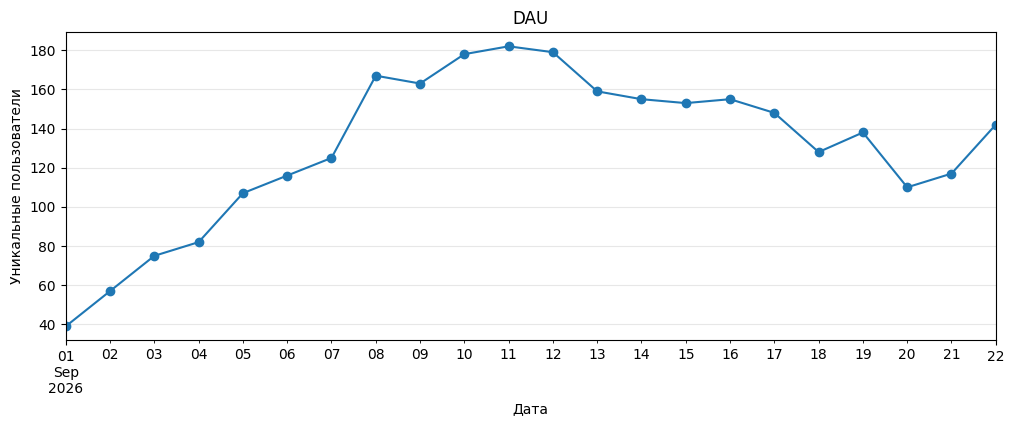

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
DAU.plot(marker = 'o')
plt.title('DAU')
plt.ylabel('Уникальные пользователи')
plt.xlabel('Дата')
plt.grid(alpha=.3)



**Вывод:** Для того, чтобы правильно рассчитать DAU, нужно было сначала убрать дубли из таблиц. Как мы выяснили ранее, они у нас были. DAU рассчитали по формуле. На графике видно кол-во пользователей в день. Отдельно также посчитали кол-во уникальных активных пользователей за весь период.

## 3. Конверсия (15 баллов)
Вычисли user conversion в первую покупку за наблюдаемое окно. Отдельно посчитай долю пользователей с add_to_cart. Объясни знаменатели.

In [ ]:
all_users = set(users['user_id'])
purchases_per_user = set(events_new.loc[events_new['event_name']=='purchase','user_id'])

purchase_user_conversion = len(purchases_per_user) / len(all_users)
print(f'\nДоля уникальный пользователей, которые совершили покупку за окно: \n {purchase_user_conversion:.2%}' )



Доля уникальный пользователей, которые совершили покупку за окно: 
 64.83%


In [ ]:
add_to_cart_users = set(events_new.loc[events_new['event_name']=='add_to_cart','user_id'])
add_to_cart_conversion = len(add_to_cart_users) / len(all_users)
print(f'\nДоля уникальный пользователей, которые добавили товар в корзину: \n {add_to_cart_conversion:.2%}' )


Доля уникальный пользователей, которые добавили товар в корзину: 
 86.33%


**Вывод:** Видно, что доля людей, которые просто добавили товары в корзину отличается на 20% от доли людей, которые совершили покупку. Окном наблюдения мы считаем весь период данных. Если бы мы брали какое-то ограниченное окно, то пришлось бы явно указывать самую раннюю дату покупки и проверять вхождение в окно. В обеих метриках мы в знаменателе используем кол-во всех зарегистрированных пользователей. В числителе для покупки используем пользователей, у которых есть хотя бы 1 событие Purchase; а для корзины используем тех, у кого есть хотя бы 1 событие add_to_cart.

## 4. Retention (20 баллов)
Рассчитай exact Day-1 и Day-7 retention по когортам даты регистрации. Исключи неполностью наблюдаемые когорты. Построй таблицу по когортам.

In [ ]:
signup_date = users[['user_id','signup_date']]
events_with_signup_date = events_new.merge(signup_date, on ='user_id', how = 'left')

events_with_signup_date.head()


,user_id,event_date,event_name,revenue_rub,signup_date
0,1,2026-09-02,app_open,0.0,2026-09-02
1,1,2026-09-02,product_view,0.0,2026-09-02
2,1,2026-09-02,add_to_cart,0.0,2026-09-02
3,1,2026-09-05,app_open,0.0,2026-09-02
4,1,2026-09-05,product_view,0.0,2026-09-02


In [ ]:
events_with_signup_date['signup_days'] = (events_with_signup_date['event_date'] - events_with_signup_date['signup_date']).dt.days

events_with_signup_date.head()

,user_id,event_date,event_name,revenue_rub,signup_date,signup_days
0,1,2026-09-02,app_open,0.0,2026-09-02,0
1,1,2026-09-02,product_view,0.0,2026-09-02,0
2,1,2026-09-02,add_to_cart,0.0,2026-09-02,0
3,1,2026-09-05,app_open,0.0,2026-09-02,3
4,1,2026-09-05,product_view,0.0,2026-09-02,3


In [ ]:
users['cohort'] = users['signup_date'].dt.date
events_with_signup_date['cohort'] = events_with_signup_date['signup_date'].dt.date

last_date = events_new['event_date'].max().date()
print('\nПоследняя дата в таблице с событиями: \n', last_date)
print('\nКогорты:\n', sorted(users['cohort'].unique()))


Последняя дата в таблице с событиями: 
 2026-09-22

Когорты 
 [datetime.date(2026, 9, 1), datetime.date(2026, 9, 2), datetime.date(2026, 9, 3), datetime.date(2026, 9, 4), datetime.date(2026, 9, 5), datetime.date(2026, 9, 6), datetime.date(2026, 9, 7), datetime.date(2026, 9, 8), datetime.date(2026, 9, 9), datetime.date(2026, 9, 10), datetime.date(2026, 9, 11), datetime.date(2026, 9, 12)]


In [ ]:
rows = []

for cohort in sorted(users['cohort'].unique()):
  size = users[users['cohort'] == cohort]['user_id'].nunique()

  if cohort + pd.Timedelta(days = 1)<= last_date:
    active_1 = events_with_signup_date[(events_with_signup_date['cohort'] == cohort) & (events_with_signup_date['signup_days'] == 1)]['user_id'].nunique()
    retention_1 = active_1/size
  else:
    retention_1 = None


  if cohort + pd.Timedelta(days = 7)<= last_date:
    active_7 = events_with_signup_date[(events_with_signup_date['cohort'] == cohort) & (events_with_signup_date['signup_days'] == 7)]['user_id'].nunique()
    retention_7 = active_7/size
  else:
    retention_7 = None


  rows.append({
      'cohort': cohort,
      'size': size,
      'Day-1 retention': None if retention_1 is None else round(retention_1*100,2),
      'Day-7 retention': None if retention_7 is None else round(retention_7*100,2)
  })



In [ ]:
retention_table = pd.DataFrame(rows)
print(retention_table.to_string(index = False))

    cohort  size  Day-1 retention  Day-7 retention
2026-09-01    52            32.69            28.85
2026-09-02    50            34.00            16.00
2026-09-03    47            31.91            34.04
2026-09-04    48            35.42            20.83
2026-09-05    38            23.68            13.16
2026-09-06    55            32.73            21.82
2026-09-07    53            43.40            16.98
2026-09-08    53            30.19            22.64
2026-09-09    54            27.78            12.96
2026-09-10    60            26.67            20.00
2026-09-11    41            24.39            24.39
2026-09-12    49            28.57            24.49


In [ ]:
day_1 = retention_table.dropna(subset = ['Day-1 retention'])
day_7 = retention_table.dropna(subset = ['Day-7 retention'])

day_1_active = (day_1['Day-1 retention'] / 100 * day_1['size']).sum()
day_7_active = (day_7['Day-7 retention'] / 100 * day_7['size']).sum()


retention_day_1 = day_1_active * 100 / day_1['size'].sum()
retention_day_7 = day_7_active * 100 / day_7['size'].sum()
print(f"\nDay-1 retention: {retention_day_1:.2f}%")
print(f"\nDay-7 retention: {retention_day_7:.2f}%")



Day-1 retention: 31.17%

Day-7 retention: 21.33%


**Вывод:** Здесь нам нужно посчитать, сколько пользователей было активно имеено в n-ный день. В нашем случае в 1 и в 7. Для этого также необходимо было оттталкиваться от даты регистрации пользователя. Те данные, которые не подходили по условиям когорт, мы не брали. Мы считаем retention здесь как кол-во активных пользователей, поделенное на кол-во пользователей в нашей когорте. Благодаря retention мы видим, сколько пользователей вернулось после регистрации и было активно в определенный день.

## 5. Деньги (15 баллов)
Рассчитай Revenue, ARPU, ARPPU и AOV по всему доступному периоду. Объясни, чем они различаются и какие бизнес-выводы ограничены данными.

In [ ]:
purchases = events_new[events_new['event_name'] == 'purchase']

revenue = purchases['revenue_rub'].sum()
users_count = users['user_id'].nunique()
orders_count = len(purchases)
buyers_count = purchases['user_id'].nunique()


ARPU = revenue/users_count
ARPPU = revenue/buyers_count
AOV = revenue/orders_count

print(f'Revenue: {orders_count} покупок на сумму {revenue:,.0f} руб.')
print(f'ARPU: средний доход на одного активного пользователя {ARPU:,.0f} руб.')
print(f'ARPPU: средний доход на одного платящего пользователя {ARPPU:,.0f} руб.')
print(f'AOV: в среднем клиент тратит {AOV:,.0f} руб.')


Revenue: 663 покупок на сумму 738,970 руб.
ARPU: средний доход на одного активного пользователя 1,232 руб.
ARPPU: средний доход на одного платящего пользователя 1,900 руб.
AOV: в среднем клиент тратит 1,115 руб.


**Вывод:** Здесь мы рассчитали кол-во заказов за период и выручку. Прибыль мы не считали, показатели будут отличаться. Также тут рассчитан средний доход на одного плятящего и активного пользователя + сколько клиент тратит в среднем. Очевидно, что arpru будет выше, чем arpu, как у нас тут и получилось.

## 6. Каналы (15 баллов)
Сравни по каналу organic и paid: число пользователей, конверсию и выручку на пользователя. Не делай причинного вывода на основе наблюдательных различий.

In [ ]:
channels = users[['user_id','channel']]

channels_of_purchases = purchases.merge(channels, on = 'user_id', how = 'left')

for ch in ['organic','paid']:
  users_count = users[users['channel'] ==ch]['user_id'].nunique()
  channel_revenue = channels_of_purchases[channels_of_purchases['channel']==ch]['revenue_rub'].sum()
  channel_conversion = channels_of_purchases[channels_of_purchases['channel']==ch]['user_id'].nunique()

  print(f'Канал привлечения: {ch}')
  print(f'Кол-во пользователей: {users_count}')
  print(f'Выручка: {channel_revenue / users_count:,.0f} руб.')
  print(f'Конверсия: {channel_conversion/users_count:.2%}')
  print('\n')

Канал привлечения: organic
Кол-во пользователей: 372
Выручка: 1,327 руб.
Конверсия: 67.74%


Канал привлечения: paid
Кол-во пользователей: 228
Выручка: 1,076 руб.
Конверсия: 60.09%




**Вывод:** При сравнении двух каналов мы видим четко кол-во пользователей, конверсию и выручку на пользователя для каждого из каналов. Мы не можем делать выводы только на основе метрик, так как не знаем, как именно в этих каналах построено привлечение, что там за люди и тд. Мы можем сравнивать только похожие друг на друга группы. Для того, чтобы провести сравнение групп, необходимо сначала оценить популяцию самих групп, возраст, по какой рекламе они переходили и тд.

## 7. Продуктовая гипотеза (10 баллов)
Предложи одну гипотезу улучшения продукта. Опиши primary, две secondary, guardrail, направление ожидаемых изменений и риски.

**Вывод:** Мы хотим увеличить кол-во заказов у клиентов, сделать так, чтобы они больше покупали. Если у нас до этого не было бесплатной доставки, то стоит ее добавить. Либо полностью бесплатную доставку, либо, например, показывать остаточную сумму, которую нужно добрать до бесплатной доставки.

Одним из главных показателей, которые мы хотим увеличить, будет средний чек на пользователя, так как клиент будет видеть плашку с оставшейся суммой и будет стараться добрать товаров, чтобы получить бесплатную доставку. Вторичными метриками, которые мы будем смотреть, будут являться add_to_cart_conversion и purchase_per_user_conversion. Guardrale: будем также смотреть на долю возвратов.

Конечно, скорее всего, люди будут добивать сумму в корзине дешевыми товарами. Это может также влиять на расчет популярных позиций на сайте. Или люди будут специально брать много дешевых товаров, чтобы получить бесплатную доставку. Средний чек может уменьшиться, а конверсия увеличиться.